# Task 2: Random Forest and feature importance,which variables have the greatest influence on the model's predictions with telco customer churn

In [16]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

SEED = 42
TELCO_PATH = "/kaggle/input/datasets/blastchar/telco-customer-churn/WA_Fn-UseC_-Telco-Customer-Churn.csv"

## Step 1: Prepare the data

After the same cleaning as Task 1, there are 7,043 customers and 19 features, with a 26.5% churn rate.I kept the text columns as they are and encode them inside the model pipeline later. A random forest doesn't need scaling, and encoding inside the pipeline keeps cross-validation honest.

In [17]:
df = pd.read_csv(TELCO_PATH)

df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce").fillna(0)
df = df.drop_duplicates()
df = df.drop(columns="customerID")

y = df["Churn"].map({"No": 0, "Yes": 1})
X = df.drop(columns="Churn")

categorical_columns = X.select_dtypes(exclude="number").columns.tolist()
print(X.shape, "| churn rate:", round(y.mean(), 3))
print(len(categorical_columns), "text columns")

(7043, 19) | churn rate: 0.265
15 text columns


## Step 2: Train/test split

Train 5,634, test 1,409, churn 0.265 in both 80/20, stratify, seed 42 More training rows help learning, more test rows make the score reliable (5% test is about 352 customers, about 93 churners, so the score would be noisy); stratify keeps the class ratio; seed makes it reproducible; trees ask one-column threshold questions, so scaling changes nothing

In [18]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)

print(X_train.shape, X_test.shape)
print(round(y_train.mean(), 3), round(y_test.mean(), 3))

(5634, 19) (1409, 19)
0.265 0.265


## Step 3: Baselines

Always-stay: accuracy 0.735, AUC 0.5. Default forest: train accuracy 0.998 vs validation 0.788; AUC 1.0 vs 0.821	The default forest overfits	No depth limit, so trees memorize the training rows; gap is about 0.21 in accuracy and 0.18 in AUC

In [19]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate

def make_model(**forest_settings):
    encoder = ColumnTransformer(
        [("text_columns", OneHotEncoder(handle_unknown="ignore"), categorical_columns)],
        remainder="passthrough", sparse_threshold=0)
    forest = RandomForestClassifier(class_weight="balanced", random_state=SEED, n_jobs=-1, **forest_settings)
    return Pipeline([("encode", encoder), ("forest", forest)])

folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

def score_model(model):
    results = cross_validate(model, X_train, y_train, cv=folds,
                             scoring=["accuracy", "roc_auc"], return_train_score=True)
    return {name: round(results[name].mean(), 3)
            for name in ["train_accuracy", "test_accuracy", "train_roc_auc", "test_roc_auc"]}

In [20]:
from sklearn.dummy import DummyClassifier

always_stay = Pipeline([("dummy", DummyClassifier(strategy="most_frequent"))])
print("always-stay baseline:", score_model(always_stay))
print("default forest      :", score_model(make_model()))

always-stay baseline: {'train_accuracy': np.float64(0.735), 'test_accuracy': np.float64(0.735), 'train_roc_auc': np.float64(0.5), 'test_roc_auc': np.float64(0.5)}
default forest      : {'train_accuracy': np.float64(0.998), 'test_accuracy': np.float64(0.788), 'train_roc_auc': np.float64(1.0), 'test_roc_auc': np.float64(0.821)}


## Step 4: Choosing n-estimators and max depth

50 to 500 trees changes validation AUC by at most 0.002 at depths 3 to 10 (0.006 unlimited). Depth with 200 trees: 0.839 (3), 0.847 (6), 0.843 (10), 0.822 (none); gaps 0.005, 0.026, 0.108, 0.178	50 trees, depth 6	Rule: simplest within 0.002 of best (0.847; this one is 0.846); more trees add nothing; depth beyond 6 overfits; depth 3 is simpler but 0.010 lower; gap 0.027 vs 0.108 at depth 10

In [21]:
grid_rows = []
for number_of_trees in [50, 200, 500]:
    for depth_limit in [3, 6, 10, None]:
        scores = score_model(make_model(n_estimators=number_of_trees, max_depth=depth_limit))
        grid_rows.append({
            "n_estimators": number_of_trees,
            "max_depth": depth_limit,
            "train_auc": scores["train_roc_auc"],
            "validation_auc": scores["test_roc_auc"]})

grid = pd.DataFrame(grid_rows)
grid["gap"] = (grid["train_auc"] - grid["validation_auc"]).round(3)
grid

,n_estimators,max_depth,train_auc,validation_auc,gap
0,50,3.0,0.843,0.837,0.006
1,50,6.0,0.873,0.846,0.027
2,50,10.0,0.950,0.841,0.109
3,50,NaN,1.000,0.817,0.183
4,200,3.0,0.844,0.839,0.005
5,200,6.0,0.873,0.847,0.026
6,200,10.0,0.951,0.843,0.108
7,200,NaN,1.000,0.822,0.178
8,500,3.0,0.845,0.839,0.006
9,500,6.0,0.874,0.847,0.027


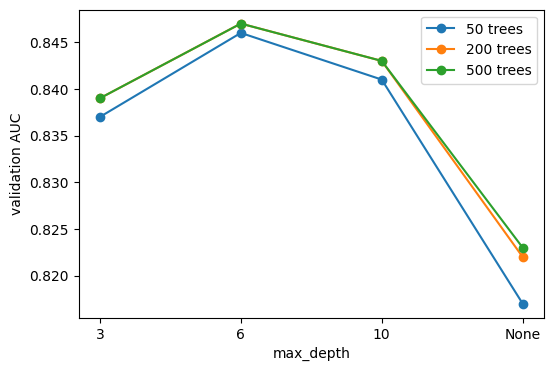

In [22]:
depth_labels = ["3", "6", "10", "None"]          
fig, ax = plt.subplots(figsize=(6, 4))
for trees, rows in grid.groupby("n_estimators"):
    ax.plot(range(len(depth_labels)), rows["validation_auc"].values, marker="o", label=f"{trees} trees")
ax.set_xticks(range(len(depth_labels)))
ax.set_xticklabels(depth_labels)
ax.set_xlabel("max_depth")
ax.set_ylabel("validation AUC")
ax.legend()
plt.show()

## Step 5: Final test

Accuracy 0.744 (baseline 0.735); AUC 0.84 (cross-validation 0.846); churn recall 0.794 (297 of 374), precision 0.511 (297 of 581 flagged); matrix [[751, 284], [77, 297]]Judge by recall and AUC, not accuracy	Accuracy is under 1 point above baseline; class_weight="balanced" makes the model flag more customers, catching most churners with many false alarms; AUC close to cross-validation means the choice did not overfit the validation folds

In [23]:
from sklearn.metrics import accuracy_score, roc_auc_score, classification_report, confusion_matrix

chosen_settings = {"n_estimators": 50, "max_depth": 6}
final_model = make_model(**chosen_settings)
final_model.fit(X_train, y_train)

churn_probability = final_model.predict_proba(X_test)[:, 1]
predicted_class = final_model.predict(X_test)

print("accuracy:", round(accuracy_score(y_test, predicted_class), 3))
print("ROC AUC :", round(roc_auc_score(y_test, churn_probability), 3))
print(classification_report(y_test, predicted_class, target_names=["stay", "churn"], digits=3))
print(confusion_matrix(y_test, predicted_class))

accuracy: 0.744
ROC AUC : 0.84
              precision    recall  f1-score   support

        stay      0.907     0.726     0.806      1035
       churn      0.511     0.794     0.622       374

    accuracy                          0.744      1409
   macro avg      0.709     0.760     0.714      1409
weighted avg      0.802     0.744     0.757      1409

[[751 284]
 [ 77 297]]


## Step 6: Feature importance

Top: Contract (permutation 0.0705, impurity 0.2625) and tenure (0.0209, 0.1399), then InternetService 0.0139 and TotalCharges 0.0110. Disagreements: DeviceProtection 12th on impurity but last on permutation; OnlineSecurity 3rd vs 6th; MonthlyCharges 0.0452 vs 0.0011	Trust permutation	Impurity is computed from training data and favours columns with many split points; permutation is measured on unseen test data

In [24]:
from sklearn.inspection import permutation_importance

encoded_names = final_model.named_steps["encode"].get_feature_names_out()

def original_column(encoded_name):
    for column in sorted(categorical_columns, key=len, reverse=True):
        if encoded_name.startswith(f"text_columns__{column}_"):
            return column
    return encoded_name.split("__", 1)[1]

impurity_importance = (
    pd.Series(final_model.named_steps["forest"].feature_importances_, index=encoded_names)
    .groupby(original_column).sum())

shuffle_result = permutation_importance(
    final_model, X_test, y_test, scoring="roc_auc", n_repeats=10, random_state=SEED, n_jobs=1)
permutation_importance_scores = pd.Series(shuffle_result.importances_mean, index=X_test.columns)

importance_table = pd.DataFrame({
    "impurity": impurity_importance,
    "permutation_AUC_drop": permutation_importance_scores,
}).sort_values("permutation_AUC_drop", ascending=False)
importance_table.round(4)

,impurity,permutation_AUC_drop
Contract,0.2625,0.0705
tenure,0.1399,0.0209
InternetService,0.0941,0.0139
TotalCharges,0.0683,0.0110
TechSupport,0.1028,0.0071
OnlineSecurity,0.1150,0.0061
PaperlessBilling,0.0145,0.0020
PaymentMethod,0.0438,0.0018
MonthlyCharges,0.0452,0.0011
StreamingMovies,0.0141,0.0009


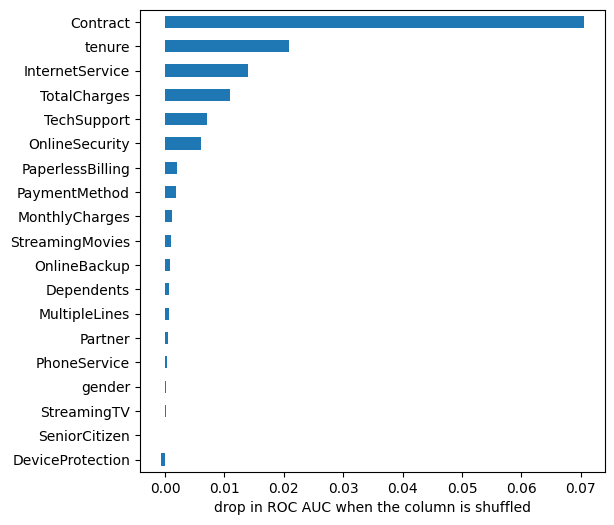

In [25]:
importance_table["permutation_AUC_drop"].sort_values().plot.barh(figsize=(6, 6))
plt.xlabel("drop in ROC AUC when the column is shuffled")
plt.show()

## Step 7: Noise check

Noise scores 0.0157 on impurity, with 9 real features below it; 0.0007 on permutation, with 11 real features at or below it and 8 clearly above; MonthlyCharges is 0.0478 vs 0.0002	Do not trust impurity for weak features A random column beating real features shows impurity's bias

In [26]:
random_generator = np.random.default_rng(SEED)

X_train_noise = X_train.copy()
X_test_noise = X_test.copy()
X_train_noise["random_noise"] = random_generator.normal(size=len(X_train_noise))
X_test_noise["random_noise"] = random_generator.normal(size=len(X_test_noise))

noise_model = make_model(**chosen_settings)
noise_model.fit(X_train_noise, y_train)

noise_names = noise_model.named_steps["encode"].get_feature_names_out()
noise_impurity = (
    pd.Series(noise_model.named_steps["forest"].feature_importances_, index=noise_names)
    .groupby(original_column).sum())

noise_shuffle = permutation_importance(
    noise_model, X_test_noise, y_test, scoring="roc_auc", n_repeats=10, random_state=SEED, n_jobs=1)

noise_table = pd.DataFrame({
    "impurity": noise_impurity,
    "permutation_AUC_drop": pd.Series(noise_shuffle.importances_mean, index=X_test_noise.columns),
})
noise_table.sort_values("impurity", ascending=False).round(4)

,impurity,permutation_AUC_drop
Contract,0.3258,0.0971
tenure,0.0980,0.0165
TechSupport,0.0948,0.0069
OnlineSecurity,0.0829,0.0065
InternetService,0.0730,0.0108
TotalCharges,0.0615,0.0091
PaymentMethod,0.0494,0.0021
MonthlyCharges,0.0478,0.0002
OnlineBackup,0.0453,0.0004
DeviceProtection,0.0378,0.0007


## Step 8: Check against the raw data

Churn 42.7% month-to-month, 11.3% one year, 2.8% two year; first year 47.4% vs 17.1% after,	Data agrees with the model,These rates explain why Contract and tenure rank first and second

In [27]:
churn_rate_by_contract = (
    df.groupby("Contract")["Churn"]
    .apply(lambda column: (column == "Yes").mean())
    .round(3))
print(churn_rate_by_contract)

in_first_year = df["tenure"] <= 12
churn_rate_by_tenure = (
    df.groupby(in_first_year)["Churn"]
    .apply(lambda column: (column == "Yes").mean())
    .round(3))
print(churn_rate_by_tenure)

Contract
Month-to-month    0.427
One year          0.113
Two year          0.028
Name: Churn, dtype: float64
tenure
False    0.171
True     0.474
Name: Churn, dtype: float64


## Interpretation and limitations

Contract and tenure dominate. Near-zero on permutation: gender, SeniorCitizen, PhoneService, Partner, Dependents, MultipleLines,Business action: target new month-to-month customers, for example an offer to move to an annual contract,A near-zero score does not prove uselessness: MonthlyCharges is probably redundant with tenure and TotalCharges. Limits: correlated features share credit, importance is not causation, one split and one seed